In [2]:
pip install numpy pandas matplotlib seaborn scikit-learn statsmodels scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


ORIGINAL DATASET:
   Unnamed: 0                              College_Name       State    UG_fee  \
0           0    Indian Institute of Technology Madras   Tamil nadu     75116   
1           1  College of Engineering, Anna University   Tamil nadu     50000   
2           2              NIT Trichy, Tiruchirappalli   Tamil nadu  1,49,250   
3           3          Vellore Institute of Technology   Tamil nadu  1,98,000   
4           4     SRM Engineering College, Kanchipuram   Tamil nadu  2,60,000   

     PG_fee Rating Academic Accommodation Faculty Infrastructure Placement  \
0     23070    8.7        9           7.9     8.7            8.8       8.8   
1     50000    8.4      8.7           7.7     8.1            8.7       8.3   
2     99250    8.5      8.6           7.8     8.2            8.7       8.8   
3  1,83,000    8.3      8.3             8     7.8            8.9       8.5   
4  1,70,000    7.2      6.5           6.6     6.9            7.6       7.1   

  Social_Life  
0         

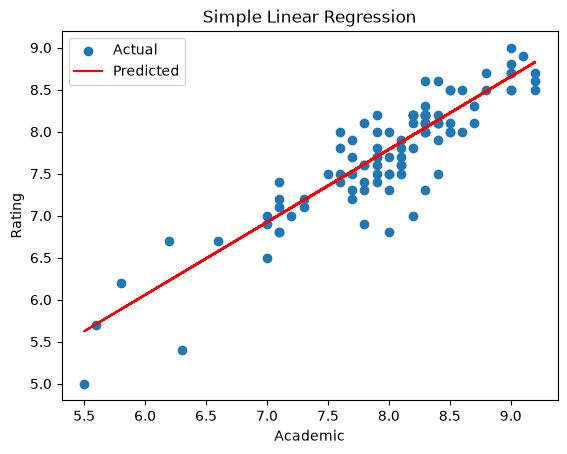


--- MULTIPLE LINEAR REGRESSION ---
Intercept: -0.017553974223951663
Coefficients: [8.74462148e-09 1.91220866e-08 1.69641897e-01 1.64777451e-01
 1.65388306e-01 1.69762948e-01 1.70079794e-01 1.63698577e-01]
R2 Score: 0.9985562638314796
Mean Squared Error: 0.0007313533502159303

--- REGRESSION ASSUMPTIONS ---


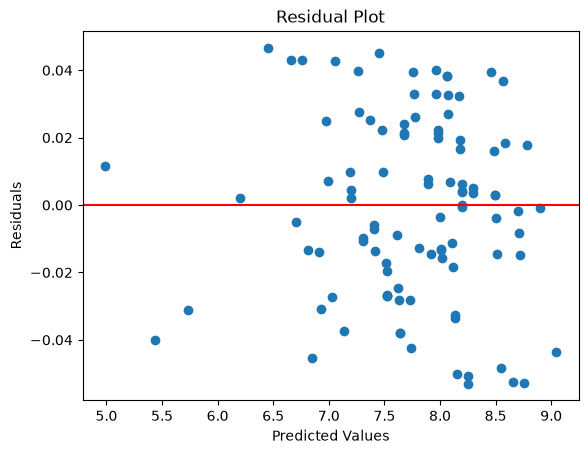

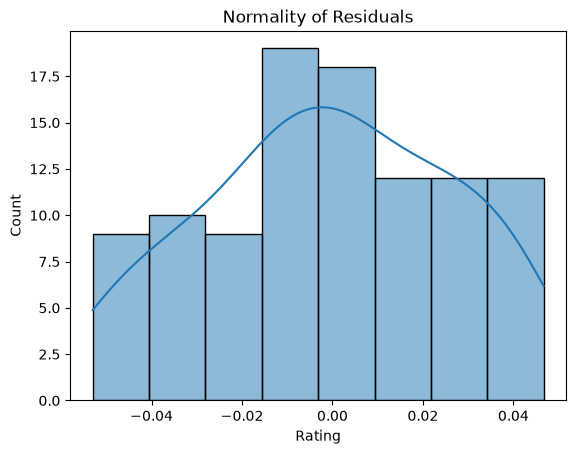

Normality Test P-value: 0.00924697967920803
Residuals may not be normally distributed
Durbin Watson Score: 2.0169223233455247

VIF VALUES:
UG_fee : 1.5914033326440211
PG_fee : 1.5951857763626678
Academic : 3.5521048454467397
Accommodation : 2.1284477693071064
Faculty : 2.79105943279812
Infrastructure : 1.9063252585071848
Placement : 2.166799244386404
Social_Life : 2.000021106909935

--- PRINCIPAL COMPONENT ANALYSIS ---

PCA RESULT:
        PC1       PC2
0  2.706374 -1.559342
1  1.549884 -1.191079
2  1.981490 -0.212021
3  1.621652  0.979800
4 -2.408929  1.975674

EXPLAINED VARIANCE RATIO:
[0.50619947 0.19368679]
TOTAL EXPLAINED VARIANCE: 0.6998862638435202


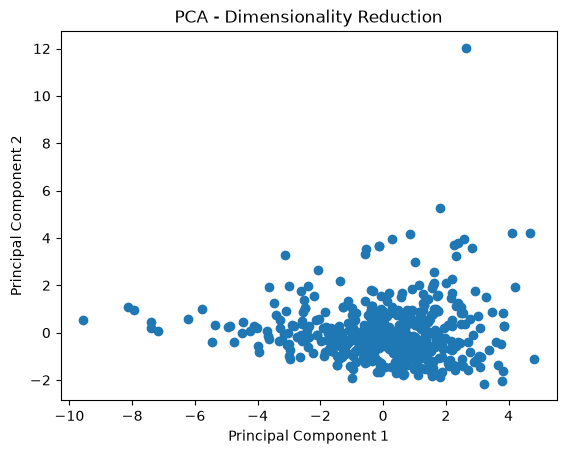


PROGRAM EXECUTED SUCCESSFULLY


In [5]:

# SIMPLE LINEAR REGRESSION
# MULTIPLE LINEAR REGRESSION
# CHECKING REGRESSION ASSUMPTIONS
# PRINCIPAL COMPONENT ANALYSIS (PCA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from scipy.stats import normaltest

# 1. LOAD DATASET

file_path = r"Colleges_Dataset.csv"

df = pd.read_csv(file_path)

print("ORIGINAL DATASET:")
print(df.head())

print("\nDATASET INFORMATION:")
print(df.info())

# 2. DATA PREPROCESSING

# Remove unnecessary index column
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Convert fee columns into numeric values
for col in ['UG_fee', 'PG_fee']:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '', regex=False),
        errors='coerce'
    )

# Convert rating columns into numeric values
rating_columns = [
    'Rating', 'Academic', 'Accommodation',
    'Faculty', 'Infrastructure', 'Placement',
    'Social_Life'
]

for col in rating_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove missing values
df = df.dropna()

print("\nCLEANED DATASET:")
print(df.head())

# 3. SELECT TARGET AND FEATURES

target_column = 'Rating'

X = df.drop(columns=[
    'Rating', 'College_Name', 'State'
])

y = df[target_column]

# 4. SIMPLE LINEAR REGRESSION

print("\n--- SIMPLE LINEAR REGRESSION ---")

X_simple = X[['Academic']]

X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

slr = LinearRegression()
slr.fit(X_train, y_train)

y_pred = slr.predict(X_test)

print("Intercept:", slr.intercept_)
print("Coefficient:", slr.coef_)
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test, y_pred, color='red', label="Predicted")
plt.xlabel("Academic")
plt.ylabel("Rating")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

# 5. MULTIPLE LINEAR REGRESSION

print("\n--- MULTIPLE LINEAR REGRESSION ---")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

mlr = LinearRegression()
mlr.fit(X_train, y_train)

y_pred = mlr.predict(X_test)

print("Intercept:", mlr.intercept_)
print("Coefficients:", mlr.coef_)
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

# 6. CHECKING REGRESSION ASSUMPTIONS

print("\n--- REGRESSION ASSUMPTIONS ---")

residuals = y_test - y_pred

# Linearity and Homoscedasticity
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

# Normality of Residuals
plt.figure()
sns.histplot(residuals, kde=True)
plt.title("Normality of Residuals")
plt.show()

if len(residuals) >= 8:
    stat, p_value = normaltest(residuals)
    print("Normality Test P-value:", p_value)

    if p_value > 0.05:
        print("Residuals are approximately normal")
    else:
        print("Residuals may not be normally distributed")

# Independence of Errors
print("Durbin Watson Score:", durbin_watson(residuals))

# Multicollinearity using VIF
print("\nVIF VALUES:")

scaler_vif = StandardScaler()
X_vif = scaler_vif.fit_transform(X_train)

for i, col in enumerate(X.columns):
    vif = variance_inflation_factor(X_vif, i)
    print(col, ":", vif)

# 7. PRINCIPAL COMPONENT ANALYSIS (PCA)

print("\n--- PRINCIPAL COMPONENT ANALYSIS ---")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)

pca_result = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pca_result,
    columns=['PC1', 'PC2']
)

print("\nPCA RESULT:")
print(pca_df.head())

print("\nEXPLAINED VARIANCE RATIO:")
print(pca.explained_variance_ratio_)

print("TOTAL EXPLAINED VARIANCE:",
      sum(pca.explained_variance_ratio_))

# PCA Visualization
plt.scatter(pca_df['PC1'], pca_df['PC2'])
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Dimensionality Reduction")
plt.show()

print("\nPROGRAM EXECUTED SUCCESSFULLY")
